In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display


# 1. Chargement et exploration des donnés d'entrainements (EDA)

--- 1. CHARGEMENT ET EDA ---
Set with labels (our train+test) : (284580, 6)


,country,age,new_user,source,total_pages_visited,converted
0,China,22,1,Direct,2,0
1,UK,21,1,Ads,3,0
2,Germany,20,0,Seo,14,1
3,US,23,1,Seo,3,0
4,US,28,1,Direct,3,0



Basics statistics: 


,country,age,new_user,source,total_pages_visited,converted
count,284580,284580.000000,284580.000000,284580,284580.000000,284580.000000
unique,4,NaN,NaN,3,NaN,NaN
top,US,NaN,NaN,Seo,NaN,NaN
freq,160124,NaN,NaN,139477,NaN,NaN
mean,NaN,30.564203,0.685452,NaN,4.873252,0.032258
std,NaN,8.266789,0.464336,NaN,3.341995,0.176685
min,NaN,17.000000,0.000000,NaN,1.000000,0.000000
25%,NaN,24.000000,0.000000,NaN,2.000000,0.000000
50%,NaN,30.000000,1.000000,NaN,4.000000,0.000000
75%,NaN,36.000000,1.000000,NaN,7.000000,0.000000


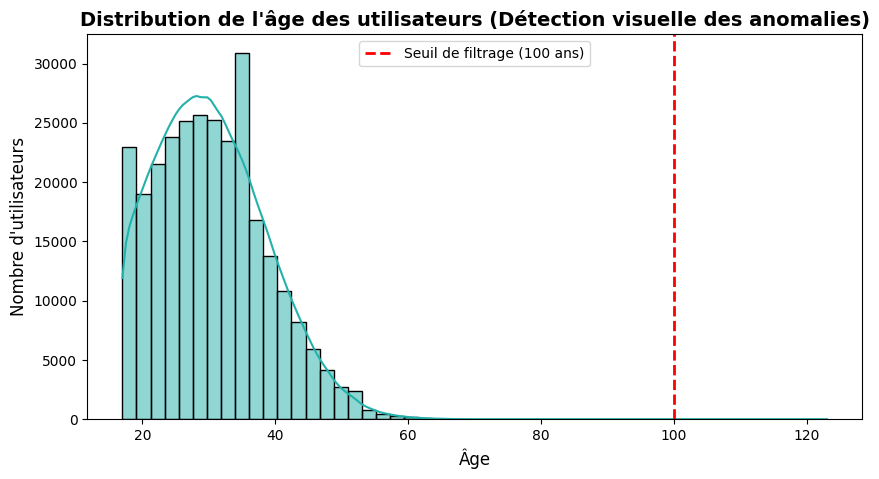

In [2]:
print("--- 1. CHARGEMENT ET EDA ---")
df = pd.read_csv('../data/conversion_data_train.csv')
print('Set with labels (our train+test) :', df.shape)
display(df.head())

print("\nBasics statistics: ")
display(df.describe(include="all"))

# EDA 1 : Analyse de la distribution de l'âge (Détection des Outliers - Matplotlib/Seaborn)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
sns.histplot(df['age'], bins=50, kde=True, color='#23B1AB')
plt.title("Distribution de l'âge des utilisateurs (Détection visuelle des anomalies)", fontsize=14, fontweight='bold')
plt.xlabel("Âge", fontsize=12)
plt.ylabel("Nombre d'utilisateurs", fontsize=12)
# Ajout d'une ligne verticale rouge pour marquer la limite du filtrage (ex: 100 ans)
plt.axvline(x=100, color='red', linestyle='--', linewidth=2, label="Seuil de filtrage (100 ans)")
plt.legend()
plt.show()

# EDA 2 : Taux de conversion par Pays (Plotly)
conversion_by_country = df.groupby('country')['converted'].mean().reset_index()
fig_country = px.bar(
    conversion_by_country, 
    x='country', y='converted', 
    title="Taux de conversion moyen par pays",
    labels={'converted': 'Taux de Conversion', 'country': 'Pays'},
    color='converted',
    color_continuous_scale='Blues'
)
fig_country.show()


In [3]:
# Nettoyage des outliers & séparation des features

print("\n--- 2. NETTOYAGE ET SÉPARATION ---")
# Filtre des valeurs aberrantes (Ex: utilisateurs de plus de 100 ans)
df = df[df['age'] < 100]
print(f"Dimensions après suppression des outliers : {df.shape}")

features_list = ['country', 'age', 'new_user', 'source', 'total_pages_visited']
target_variable = 'converted'
X = df[features_list]
Y = df[target_variable]


--- 2. NETTOYAGE ET SÉPARATION ---
Dimensions après suppression des outliers : (284578, 6)


In [4]:
# 3. split Train / Test (avec stratification pour le déséquilibre 97/3)
print("\n--- 3. SPLIT STRATIFIÉ ---")
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=0)
print("Dimensions du Train set :", X_train.shape)


--- 3. SPLIT STRATIFIÉ ---
Dimensions du Train set : (227662, 5)


In [5]:
# 4. preprocessin (Pipeline anti-data leakage)
print("\n--- 4. PREPROCESSING ---")
numeric_features = ['age', 'total_pages_visited']
categorical_features = ['country', 'new_user', 'source']

featureencoder = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ])

# Fit_transform sur le Train, transform strict sur le Test
X_train_processed = featureencoder.fit_transform(X_train)
X_test_processed = featureencoder.transform(X_test)
print("Preprocessing appliqué avec succès.")


--- 4. PREPROCESSING ---
Preprocessing appliqué avec succès.


In [6]:
# 5. Modelisation de base (Baseline): Random Forest)
print("\n--- 5. BASELINE MODEL (Random Forest) ---")
baseline_rf = RandomForestClassifier(class_weight='balanced', random_state=0)
baseline_rf.fit(X_train_processed, Y_train)
rf_pred = baseline_rf.predict(X_test_processed)
print(f"Baseline F1-Score (Random Forest) : {f1_score(Y_test, rf_pred):.4f}")


--- 5. BASELINE MODEL (Random Forest) ---
Baseline F1-Score (Random Forest) : 0.5674


In [7]:
# 6. Optimisation du modèle final(GRIDSEARCH + RÉGRESSION LOGISTIQUE)
print("\n--- 6. OPTIMISATION (Logistic Regression + GridSearchCV) ---")
# On cherche le meilleur hyperparamètre 'C' (inverse de la régularisation)
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=0),
    param_grid,
    cv=5, # K-Fold Cross Validation
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train_processed, Y_train)
print("Meilleur hyperparamètre C :", grid_search.best_params_['C'])
print("Meilleur F1-Score en Validation Croisée :", grid_search.best_score_)

best_classifier = grid_search.best_estimator_


--- 6. OPTIMISATION (Logistic Regression + GridSearchCV) ---
Meilleur hyperparamètre C : 1
Meilleur F1-Score en Validation Croisée : 0.7631206327651971



--- 7. ÉVALUATION FINALE ---
F1-score final sur Test set :  0.7633633633633634

Classification Report :
               precision    recall  f1-score   support

           0       0.99      1.00      0.99     55080
           1       0.85      0.69      0.76      1836

    accuracy                           0.99     56916
   macro avg       0.92      0.84      0.88     56916
weighted avg       0.99      0.99      0.99     56916



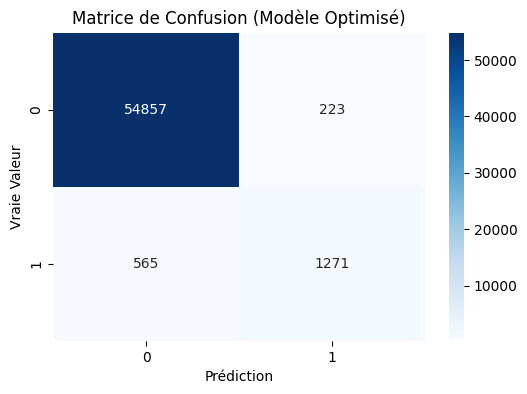

In [8]:
# Evaluation finale sur le test set (MATRICE DE CONFUSION)
print("\n--- 7. ÉVALUATION FINALE ---")
Y_test_pred = best_classifier.predict(X_test_processed)

print("F1-score final sur Test set : ", f1_score(Y_test, Y_test_pred))
print("\nClassification Report :\n", classification_report(Y_test, Y_test_pred))

# Affichage visuel de la Matrice de Confusion
plt.figure(figsize=(6,4))
import seaborn as sns
sns.heatmap(confusion_matrix(Y_test, Y_test_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Matrice de Confusion (Modèle Optimisé)")
plt.ylabel('Vraie Valeur')
plt.xlabel('Prédiction')
plt.show()

In [9]:
# 8. entrainement Global 
print("\n--- 8. GÉNÉRATION DE LA SOUMISSION KAGGLE ---")
# On ré-entraîne le MEILLEUR modèle sur TOUTES les données pour maximiser les performances
X_all_processed = featureencoder.fit_transform(X)
best_classifier.fit(X_all_processed, Y)

# Chargement du fichier de test aveugle
data_without_labels = pd.read_csv('../data/conversion_data_test.csv')
X_without_labels = data_without_labels.loc[:, features_list]

# Prédiction
X_without_labels_processed = featureencoder.transform(X_without_labels)
predictions = best_classifier.predict(X_without_labels_processed)

# Export
Y_predictions = pd.DataFrame(columns=['converted'], data={'converted': predictions})
Y_predictions.to_csv('conversion_data_test_predictions_CARELLE.csv', index=False)
print("Fichier 'conversion_data_test_predictions_CARELLE.csv' créé avec succès !")


--- 8. GÉNÉRATION DE LA SOUMISSION KAGGLE ---
Fichier 'conversion_data_test_predictions_CARELLE.csv' créé avec succès !



--- 9. INTERPRÉTATION DES COEFFICIENTS ---


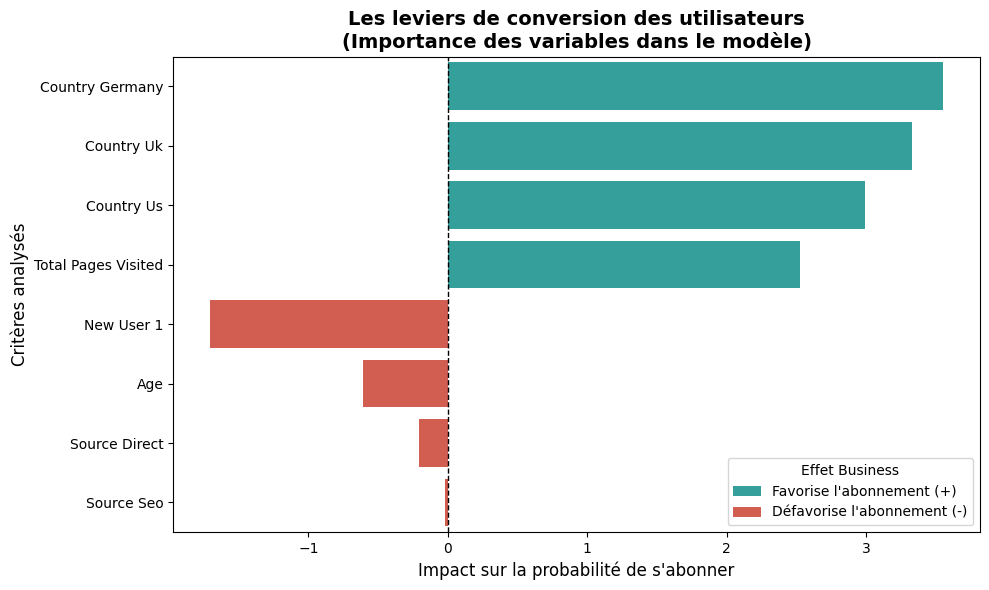

In [10]:
# 9. Interprétation Business (Leviers d'action)
print("\n--- 9. INTERPRÉTATION DES COEFFICIENTS ---")

# 1. Récupération et nettoyage des noms des variables
column_names = featureencoder.get_feature_names_out()
clean_names = [name.replace('num__', '').replace('cat__', '').replace('_', ' ').title() for name in column_names]

# 2. Création du DataFrame des coefficients
coefs = pd.DataFrame({
    'Critère': clean_names,
    'Coefficient': best_classifier.coef_[0]
})

# 3. Tri par importance absolue (les leviers les plus forts en premier)
coefs['Abs_Coefficient'] = abs(coefs['Coefficient'])
coefs = coefs.sort_values(by='Abs_Coefficient', ascending=False)

# 4. Ajout explicite de l'impact (pour le code couleur)
coefs['Impact'] = coefs['Coefficient'].apply(
    lambda x: "Favorise l'abonnement (+)" if x > 0 else "Défavorise l'abonnement (-)"
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=coefs, 
    x='Coefficient', 
    y='Critère', 
    hue='Impact', 
    palette={"Favorise l'abonnement (+)": '#23B1AB', "Défavorise l'abonnement (-)": '#E74C3C'},
    dodge=False
)

# Ajout d'une ligne verticale à 0 pour bien voir la bascule
plt.axvline(0, color='black', linestyle='--', linewidth=1)

# Mise en page propre
plt.title("Les leviers de conversion des utilisateurs\n(Importance des variables dans le modèle)", fontsize=14, fontweight='bold')
plt.xlabel("Impact sur la probabilité de s'abonner", fontsize=12)
plt.ylabel("Critères analysés", fontsize=12)
plt.legend(title="Effet Business", loc='lower right')
plt.tight_layout()
plt.show()

In [11]:
# Test rapide : régression logistique avec et sans class_weight='balanced'
print("Comparaison des F1 sur le test set...")
for poids in [None, "balanced"]:
    modele = LogisticRegression(C=0.1, class_weight=poids, max_iter=1000, random_state=0)
    modele.fit(X_train_processed, Y_train)
    prediction = modele.predict(X_test_processed)
    print("class_weight =", poids, "| F1 test =", round(f1_score(Y_test, prediction), 4))
    

Comparaison des F1 sur le test set...
class_weight = None | F1 test = 0.7621
class_weight = balanced | F1 test = 0.5089
